In [2]:
import glob
from matplotlib.pylab import seed
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)

import numpy as np

def calculate_djf_mean(ds):
    ds_seasons = ds.resample(time='QE-FEB').mean()
    ds_djf = ds_seasons.sel(time=(ds_seasons['time.season'] == 'DJF'))
    ds_djf['time'] = pd.date_range(str(ds_djf.time[0].values).split('-')[0], str(int(str(ds_djf.time[-1].values).split('-')[0]) +1), freq='YS-FEB',unit='s')
    return ds_djf


def anomaly_calculation(model, clim):
    ano_list = []
    for i in range(1,13):
        ano_list.append(model.sel(time=model.time[model.time.dt.month.isin(i)]) - clim.sel(month=i))
    return xr.concat(ano_list, dim='time').sortby('time')


def load_climatology(path):
    clim = xr.open_dataset(glob.glob(path)[0])
    clim['time'] = [1,2,3,4,5,6,7,8,9,10,11,12]
    clim = clim.rename({'time': 'month'})
    return clim

def load_data(path):
    ens = []
    ds = []
    for p in glob.glob(path):
        ens.append(p.split('/')[-1].split('_')[4])
        ds.append(xr.open_dataset(p))
    data = xr.concat(ds, dim='ens')
    data['ens'] = ens

    return data

def pressure_weighting(data, plevs=slice(7000,2000)):
    # here I select the pressure level intervall 
    # for which I want to caluculate the layer weights
    # (in this case plevs = 70 - 20 hPa)
    data = data.sel(plev=plevs)
    # Then natural logarithm of this pressure values is caluculated
    log_pressure = np.log(data.plev.values)  
    # the difference between this logaritmic pressure values is made
    log_layer_thickness = np.abs(np.diff(log_pressure))
    # then i devide these differences by the total thickness of the layer
    # = sum of the differences
    log_layer_thickness = log_layer_thickness / sum(log_layer_thickness)

    # this part just creates an array to make it compatible with the data 
    # #(no manipulation of the results done in this step)
    log_layer_thickness = xr.DataArray(
        log_layer_thickness,
        coords={"plev": data.plev.values[:-1]},  # Assign to the lower pressure level of each layer
        dims=["plev"]
    )

    # finally I multiply the data with the "normalized" thickness of the pressure layer
    data = data * log_layer_thickness

    return data.sum(dim='plev')



def bootstrap_group(sub_df, diag_cols, phase_col, n_boot=1000,
                     sample_size=10):

    rng = np.random.default_rng(seed=100) # set for reproducability
    diag_values = sub_df[diag_cols].to_numpy()

    # create phase dict to iterate  
    phase_flags = sub_df[phase_col].to_numpy()
    phases = np.unique(phase_flags)
    phase_idx = {p: np.where(phase_flags == p)[0] for p in phases}
 
    out = {} 
    for p in phases:
        out[p] = np.full((n_boot, len(diag_cols)), np.nan)
 
    for i in range(n_boot):
        for p in phases:
            idx = phase_idx[p]
            if len(idx) == 0:
                continue  # if no realizatinos in this phase, stays NaN
            draw_p = rng.choice(idx, size=sample_size, replace=True)
            out[p][i] = diag_values[draw_p].mean(axis=0)
 
    return {k: pd.DataFrame(v, columns=diag_cols) for k, v in out.items()}
 
 
def bootstrap_all_models(df, diag_cols, model_level, phase_col,
                          n_boot=1000, sample_size=10):
    # wrapper function for bootstrapping over models 
    results = {}
    for model_name, sub_df in df.groupby(level=model_level):
        out = bootstrap_group(
            sub_df, diag_cols, phase_col,
            n_boot=n_boot, sample_size=sample_size
        )
        results[model_name] = pd.concat(out).reset_index().rename(columns={'level_0': 'flag_nao'}).drop(['level_1'], axis=1)
    return results


In [20]:
path = "/sto4/data/Intermediate/VolMIP/pinatubo-full/"
path_piControl = "/sto4/data/Intermediate/VolMIP/piControl/"
models = ['CanESM5', 'GISS-E2-1-G', 'IPSL-CM6A-LR', 'MIROC-ES2L', 'MPI-ESM1-2-LR', 'UKESM1-0-LL']
plotdir = '/home/kperny/VolMIP_stratosphere/plots/PAPER/'

nao_flags = pd.read_csv('/home/kperny/VolMIP_stratosphere/tab/nao_flags.csv')
nao_flags = nao_flags.set_index(['model', 'realization'])

# read pre-calculated table for piControl
df_pi_control = pd.read_csv('/home/kperny/VolMIP_stratosphere/tab/diagnostics_piControl.csv')
df_pi_control = df_pi_control.set_index(['model', 'realization'])

In [21]:
df_volc = nao_flags.drop(['year', 'nao_pi', 'flag_pi', 'nao_volc'], axis=1)

# model = models[0]
for model in models:
    ta_volc = load_data(path + model + '/ta_AmonZ_*.nc')
    ua_volc = load_data(path + model + '/ua_AmonZ_*.nc')
    ua_clim_pi = load_climatology(path_piControl + model + '/ua_clim_AmonZ*')
    ta_clim_pi = load_climatology(path_piControl + model + '/ta_clim_AmonZ*')

    ta_ano = anomaly_calculation(ta_volc['ta'], ta_clim_pi['ta'])
    ta_volc = calculate_djf_mean(ta_ano)

    ua_ano = anomaly_calculation(ua_volc['ua'], ua_clim_pi['ua'])
    ua_volc = calculate_djf_mean(ua_ano)

    df_volc.loc[model,'deltaT_tropics'] = pressure_weighting(ta_volc.sel(time='1992-02')).sel(lat=slice(-20,20)).mean('lat').squeeze().sel(ens=df_volc.loc[model].index).values
    df_volc.loc[model,'deltaT_polar'] = pressure_weighting(ta_volc.sel(time='1992-02')).sel(lat=slice(70,90)).mean('lat').squeeze().sel(ens=df_volc.loc[model].index).values
    df_volc.loc[model,'deltaU'] = ua_volc.sel(time='1992-02').sel(lat=slice(60,70), plev=1000).mean('lat').squeeze().sel(ens=df_volc.loc[model].index).values


/tmp/ipykernel_3354406/2248364624.py:28: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  clim = xr.open_dataset(glob.glob(path)[0])
/tmp/ipykernel_3354406/2248364624.py:28: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  clim = xr.open_dataset(glob.glob(path)[0])
/tmp/ipykernel_3354406/2248364624.py:38: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds.append(x

In [22]:
# bootstrapping
results_volc = bootstrap_all_models(
        df_volc, diag_cols=['deltaT_tropics', 'deltaT_polar', 'deltaU'], model_level='model', phase_col='flag_volc',
        n_boot=100, sample_size=10)
results_pi = bootstrap_all_models(
        df_pi_control, diag_cols=['deltaT_tropics', 'deltaT_polar', 'deltaU'], model_level='model', phase_col='flag_pi',
        n_boot=100, sample_size=10)
# concat results
results_volc = pd.concat(results_volc).reset_index().rename(columns={'level_0': 'model'}).drop(['level_1'], axis=1)
results_pi = pd.concat(results_pi).reset_index().rename(columns={'level_0': 'model'}).drop(['level_1'], axis=1)

In [23]:
df_pi_control = results_pi.rename({'flag_nao': 'flag_pi'}, axis=1)
df_volc = results_volc.rename({'flag_nao': 'flag_volc'}, axis=1)

volc_tmp = results_volc
pi_tmp = results_pi
mean_all = (volc_tmp.groupby(['model', 'flag_nao']).mean() - pi_tmp.groupby(['model', 'flag_nao']).mean()).reset_index()
mean_df = mean_all.where(mean_all.flag_nao != 0).dropna()
df_all = mean_all.groupby('model').mean()
df_all['flag_nao'] = 'all'
df = pd.concat([mean_df, df_all.reset_index()])
df = df.replace({"flag_nao": {-1: 'NAO-', 1: 'NAO+'}})

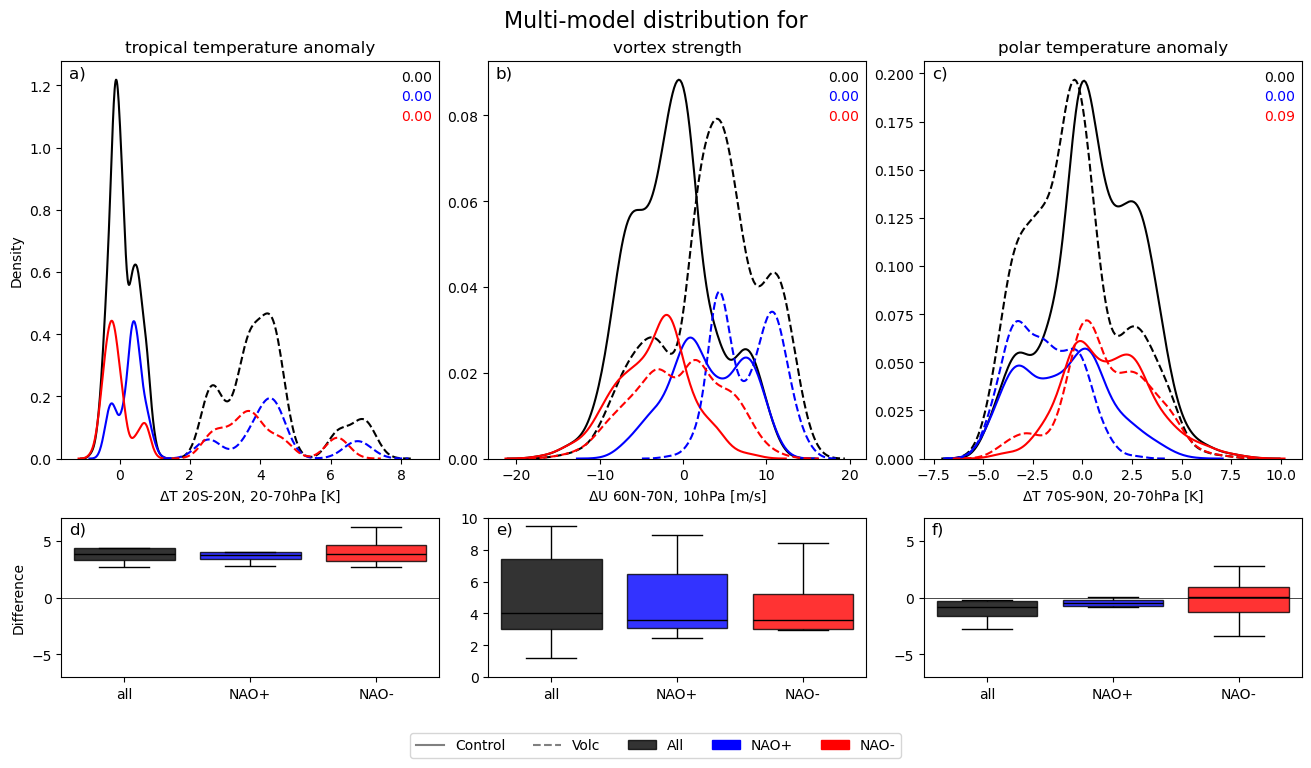

In [24]:
fig, axs = plt.subplots(2,3, figsize=(13,7), layout='constrained', gridspec_kw={'height_ratios': [5,2]})

posnao_pi = df_pi_control.where(df_pi_control.flag_pi == 1).dropna()
negnao_pi = df_pi_control.where(df_pi_control.flag_pi == -1).dropna()

posnao_volc = df_volc.where(df_volc.flag_volc == 1).dropna()
negnao_volc = df_volc.where(df_volc.flag_volc == -1).dropna()

sns.kdeplot(df_pi_control, x='deltaT_tropics', color='black', ax=axs[0,0])
sns.kdeplot(df_volc, x='deltaT_tropics', color='black', ax=axs[0,0], linestyle='--')
sns.kdeplot(df_pi_control, x='deltaT_tropics', ax=axs[0,0], hue='flag_pi', palette=['red', 'grey', 'blue'], legend=False)
lines = sns.kdeplot(df_volc, x='deltaT_tropics', ax=axs[0,0], linestyle='--', hue='flag_volc', palette=['red', 'grey', 'blue'], legend=False)

lines.lines[3].remove()
lines.lines[5].remove()

sns.kdeplot(df_pi_control, x='deltaU', color='black', ax=axs[0,1])
sns.kdeplot(df_volc, x='deltaU', color='black', ax=axs[0,1], linestyle='--')
sns.kdeplot(df_pi_control, x='deltaU', ax=axs[0,1], hue='flag_pi', palette=['red', 'grey', 'blue'], legend=False)
lines = sns.kdeplot(df_volc, x='deltaU', ax=axs[0,1], linestyle='--', hue='flag_volc', palette=['red', 'grey', 'blue'], legend=False)

lines.lines[3].remove()
lines.lines[5].remove()

sns.kdeplot(df_pi_control, x='deltaT_polar', color='black', ax=axs[0,2])
sns.kdeplot(df_volc, x='deltaT_polar', color='black', ax=axs[0,2], linestyle='--')
sns.kdeplot(df_pi_control, x='deltaT_polar', ax=axs[0,2], hue='flag_pi', palette=['red', 'grey', 'blue'], legend=False)
lines = sns.kdeplot(df_volc, x='deltaT_polar', ax=axs[0,2], linestyle='--', hue='flag_volc', palette=['red', 'grey', 'blue'], legend=False)

lines.lines[3].remove()
lines.lines[5].remove()

props = None #dict(facecolor='white', alpha=0.7, edgecolor='none')

axs[0,0].text(0.90, 0.95, "{:.2f}".format(stats.kstest(df_pi_control.deltaT_tropics.values , df_volc.deltaT_tropics.values, alternative='greater')[1].round(3)), c='k', transform=axs[0,0].transAxes, bbox=props)
axs[0,0].text(0.90, 0.9,  "{:.2f}".format(stats.kstest(posnao_pi.deltaT_tropics.values , posnao_volc.deltaT_tropics.values, alternative='greater')[1].round(3)), c='b', transform=axs[0,0].transAxes, bbox=props)
axs[0,0].text(0.90, 0.85, "{:.2f}".format(stats.kstest(negnao_pi.deltaT_tropics.values , negnao_volc.deltaT_tropics.values, alternative='greater')[1].round(3)), c='r',transform=axs[0,0].transAxes, bbox=props)
axs[0,1].text(0.90, 0.95, "{:.2f}".format(stats.kstest(df_pi_control.deltaU.values , df_volc.deltaU.values, alternative='greater')[1].round(2)), c='k', transform=axs[0,1].transAxes, bbox=props)
axs[0,1].text(0.90, 0.9,  "{:.2f}".format(stats.kstest(posnao_pi.deltaU.values , posnao_volc.deltaU.values, alternative='greater')[1].round(2)), c='b', transform=axs[0,1].transAxes, bbox=props)
axs[0,1].text(0.90, 0.85, "{:.2f}".format(stats.kstest(negnao_pi.deltaU.values , negnao_volc.deltaU.values, alternative='greater')[1].round(2)), c='r',transform=axs[0,1].transAxes, bbox=props)
axs[0,2].text(0.90, 0.95, "{:.2f}".format(stats.kstest(df_pi_control.deltaT_polar.values , df_volc.deltaT_polar.values, alternative='less')[1].round(2)), c='k', transform=axs[0,2].transAxes, bbox=props)
axs[0,2].text(0.90, 0.9,  "{:.2f}".format(stats.kstest(posnao_pi.deltaT_polar.values , posnao_volc.deltaT_polar.values, alternative='less')[1].round(2)), c='b', transform=axs[0,2].transAxes, bbox=props)
axs[0,2].text(0.90, 0.85, "{:.2f}".format(stats.kstest(negnao_pi.deltaT_polar.values , negnao_volc.deltaT_polar.values, alternative='less')[1].round(2)), c='r',transform=axs[0,2].transAxes, bbox=props)

axs[0,0].set_xlabel('$\Delta$T 20S-20N, 20-70hPa [K]')
axs[0,1].set_xlabel('$\Delta$U 60N-70N, 10hPa [m/s]')
axs[0,2].set_xlabel('$\Delta$T 70S-90N, 20-70hPa [K]')
axs[0,1].set_ylabel('')
axs[0,2].set_ylabel('')

axs[0,0].annotate('a)', (0.02,0.97), xycoords='axes fraction', va='center', fontsize=12)
axs[0,1].annotate('b)', (0.02,0.97), xycoords='axes fraction', va='center', fontsize=12)
axs[0,2].annotate('c)', (0.02,0.97), xycoords='axes fraction', va='center', fontsize=12)

### ADD BOXPLOT 
sns.boxplot(data=df, ax=axs[1,0], x='flag_nao', y='deltaT_tropics', hue='flag_nao', palette={'all': 'k', 'NAO+' : 'b', 'NAO-': 'r'}, saturation=1,
            boxprops=dict(alpha=.8), showfliers=False)
sns.boxplot(data=df, ax=axs[1,1], x='flag_nao', y='deltaU', hue='flag_nao', palette={'all': 'k', 'NAO+' : 'b', 'NAO-': 'r'}, saturation=1,
            boxprops=dict(alpha=.8), showfliers=False)
sns.boxplot(data=df, ax=axs[1,2], x='flag_nao', y='deltaT_polar', hue='flag_nao', palette={'all': 'k', 'NAO+' : 'b', 'NAO-': 'r'}, saturation=1,
            boxprops=dict(alpha=.8), showfliers=False)
axs[1,0].axhline(0, color='k', linewidth=0.5)
axs[1,2].axhline(0, color='k', linewidth=0.5)
axs[1,0].invert_xaxis()
axs[1,1].invert_xaxis()
axs[1,2].invert_xaxis()
axs[1,0].set_ylabel('Difference')
axs[1,1].set_ylabel('')
axs[1,2].set_ylabel('')
axs[1,0].set_ylim(-7,7)
axs[1,1].set_ylim(0,10)
axs[1,2].set_ylim(-7,7)
axs[1,0].set_xlabel('')
axs[1,1].set_xlabel('')
axs[1,2].set_xlabel('')

axs[1,0].annotate('d)', (0.02,0.93), xycoords='axes fraction', va='center', fontsize=12)
axs[1,1].annotate('e)', (0.02,0.93), xycoords='axes fraction', va='center', fontsize=12)
axs[1,2].annotate('f)', (0.02,0.93), xycoords='axes fraction', va='center', fontsize=12)



# LEGEND
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
piControl = Line2D([0], [0], label='Control', color='grey')
volc = Line2D([0], [0], label='Volc', color='grey', linestyle='--')
all = mpatches.Patch(color='k', alpha=0.8, label='All')
ponao = mpatches.Patch(color='blue', label='NAO+')
negnao = mpatches.Patch(color='red', label='NAO-')

fig.legend(handles= [piControl, volc, all, ponao, negnao], loc='upper center', bbox_to_anchor=(0.5, -0.03), ncol=5)

# TITLES
plt.suptitle('Multi-model distribution for', fontsize=16)
axs[0,0].set_title('tropical temperature anomaly')
axs[0,1].set_title('vortex strength')
axs[0,2].set_title('polar temperature anomaly')
plt.savefig(plotdir + 'supp_figure3bootstrapped.png', dpi=200, bbox_inches='tight')